In [2]:
from pathlib import Path
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt


def get_path(line_number, config_file="paths.txt"):
    with open(config_file, "r") as f:
        lines = f.readlines()
    if len(lines) >= line_number:
        path_str = lines[line_number - 1].strip()
        return Path(path_str)
    else:
        raise IndexError(f"File has less than {line_number} lines")


def create_data_stack(directory_path, file_pattern):
    files = sorted(directory_path.glob(file_pattern))
    if not files:
        raise FileNotFoundError(f"No files found for pattern {file_pattern} in {directory_path}")
    stack = [fits.getdata(f) for f in files]
    header = fits.getheader(files[0])
    return np.array(stack), header


def create_master(data_stack, sigma=3):
    median = np.median(data_stack, axis=0)
    std = np.std(data_stack, axis=0)
    bad_pixels_mask = np.abs(data_stack - median) > (sigma * std)
    masked_stack = np.ma.masked_array(data_stack, mask=bad_pixels_mask)
    master_data = np.ma.median(masked_stack, axis=0).filled(median)
    return master_data


def save_master(directory_path, output_name, master_data, header):
    header["COMBINED"] = True
    hdu = fits.PrimaryHDU(data=master_data, header=header)
    output_path = directory_path / output_name
    hdu.writeto(output_path, overwrite=True)


def plot_histogram(data, title="FITS Data Histogram", bins=256):
    plt.figure(figsize=(10, 4))
    bins = np.linspace(0,1500,60)
    plt.hist(data.ravel(),bins=bins,label="data")
    plt.yscale('log')
    plt.title(title)
    plt.xlabel("ADU Value")
    plt.ylabel("Pixel Count")
    plt.grid(True)
    plt.show()



In [3]:
bias1_path=get_path(1)
bias1, header_bias1=create_data_stack(bias1_path, "bias_*.fit*")
bias1_master=create_master(bias1)
#save_master(bias1_path, "master_bias.fits", bias1_master, header_bias1)


In [4]:
bias15_path=get_path(5)
bias15, header_bias15=create_data_stack(bias15_path, "bias_*.fit*")
bias15_master=create_master(bias15)
#save_master(bias15_path, "master_bias.fits", bias15_master, header_bias15)


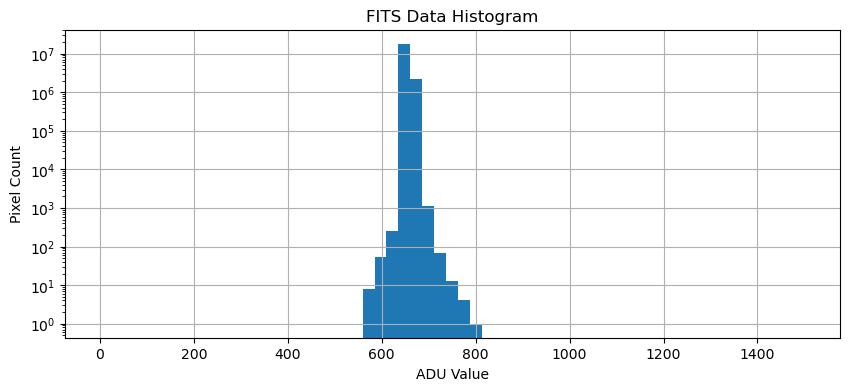

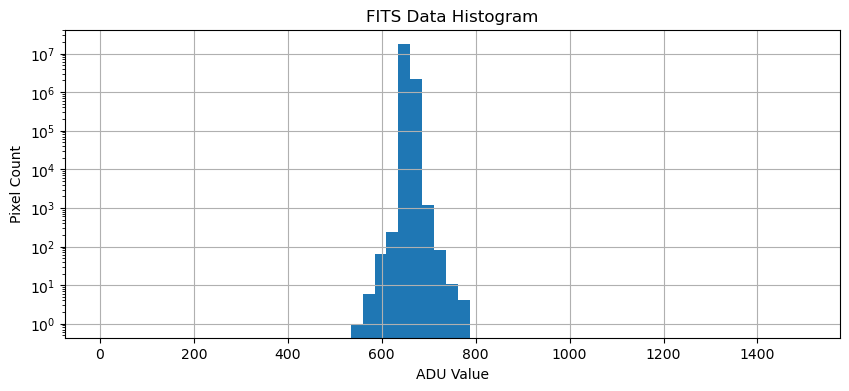

In [5]:
plot_histogram(bias1_master)
plot_histogram(bias15_master)


In [180]:
dark1_path=get_path(2)
dark1, header_dark1=create_data_stack(dark1_path, "dark_*.fit*")
dark151_master=create_master(dark1)
#save_master(dark1_path, "master_dark.fits", dark151_master, header_dark1)
dark60_path=get_path(3)
dark60, header_dark60=create_data_stack(dark60_path, "dark_*.fit*")
dark1560_master=create_master(dark60)
#save_master(dark60_path, "master_dark.fits", dark1560_master, header_dark60)
dark0_5_path=get_path(4)
dark0_5, header_dark0_5=create_data_stack(dark0_5_path, "dark_*.fit*")
dark051_master=create_master(dark0_5)
#save_master(dark0_5_path, "master_dark.fits", dark051_master, header_dark0_5)

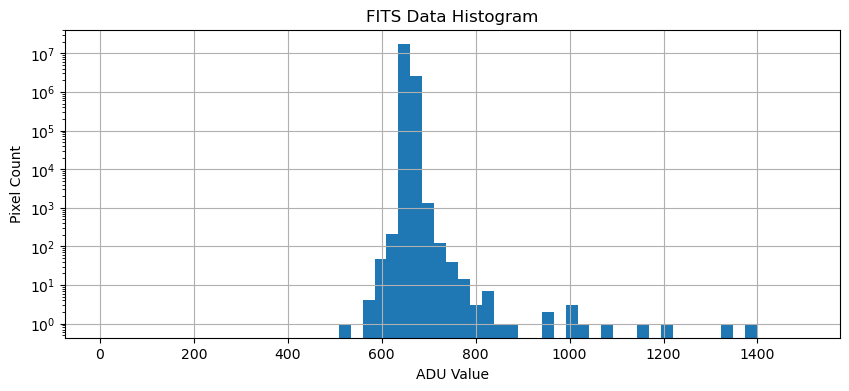

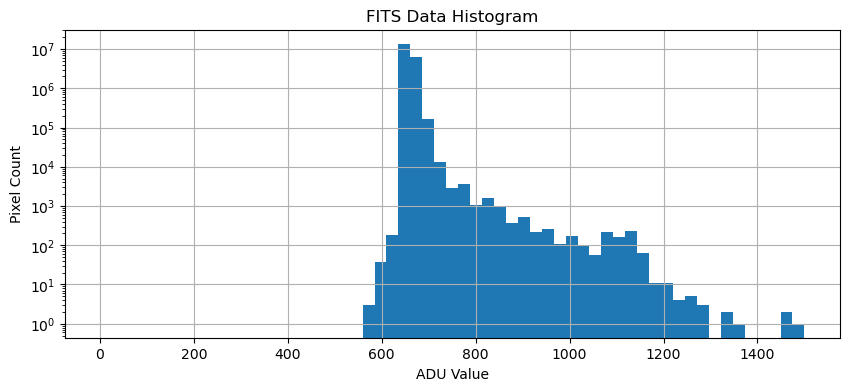

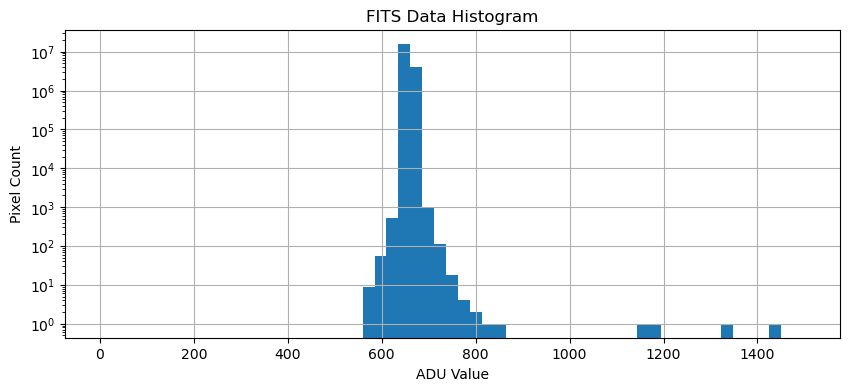

In [156]:
plot_histogram(dark1_master)
plot_histogram(dark60_master)
plot_histogram(dark0_5_master)

In [159]:
dark0510_path=get_path(7)
dark0510, header_dark0510=create_data_stack(dark0510_path, "dark_*.fit*")
dark0510_master=create_master(dark0510)
#save_master(dark0510_path, "master_dark.fit", dark0510_master, header_dark0510)


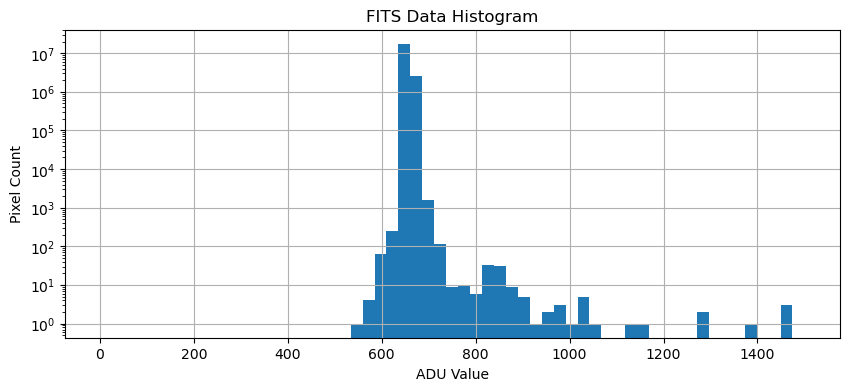

In [161]:
plot_histogram(dark0510_master)

In [164]:
dark1510_path=get_path(6)
dark1510, header_dark1510=create_data_stack(dark1510_path, "dark_*.fit*")
dark1510_master=create_master(dark1510)
#save_master(dark1510_path, "master_dark.fit", dark1510_master, header_dark1510)

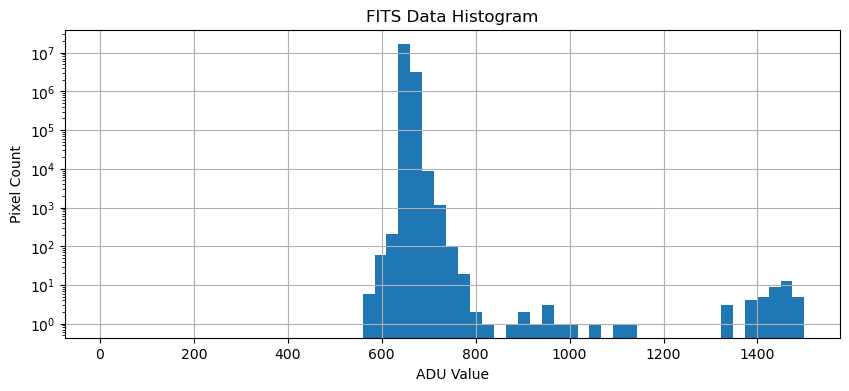

In [166]:
plot_histogram(dark1510_master)

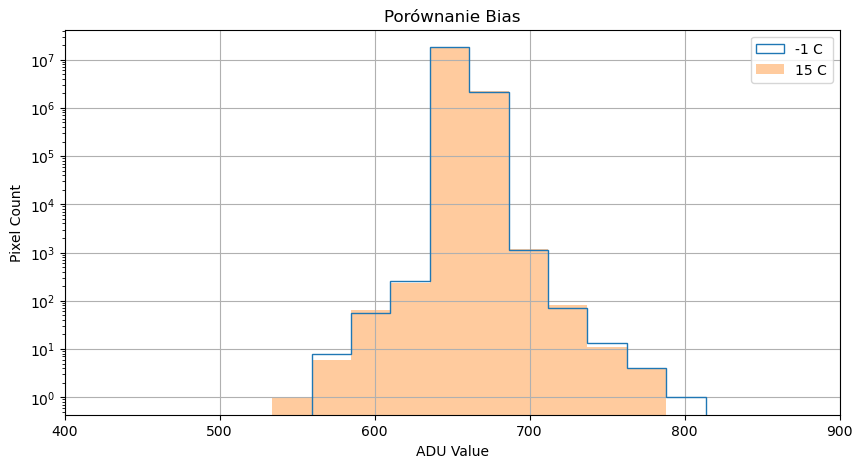

In [179]:
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 60)
plt.hist(bias1_master.ravel(),histtype="step", bins=bins, alpha=1, label="-1 C")
plt.hist(bias15_master.ravel(), bins=bins, alpha=0.4, label="15 C")
plt.xlim(400,900)
plt.yscale('log')
plt.title("Porównanie Bias")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()


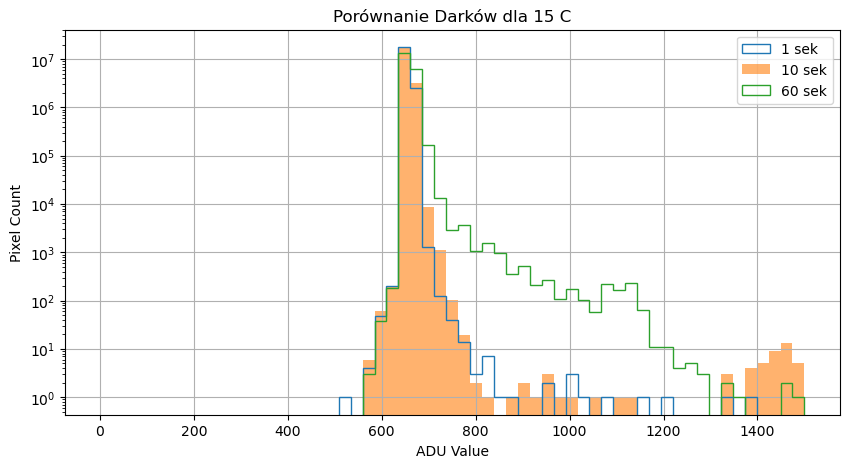

In [198]:
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 60)
plt.hist(dark151_master.ravel(),histtype="step", bins=bins, alpha=1, label="1 sek")
plt.hist(dark1510_master.ravel(), bins=bins, alpha=0.6, label="10 sek")
plt.hist(dark1560_master.ravel(), bins=bins,histtype="step", alpha=1, label="60 sek")
#plt.xlim(400,1600)
plt.yscale('log')
plt.title("Porównanie Darków dla 15 C")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()

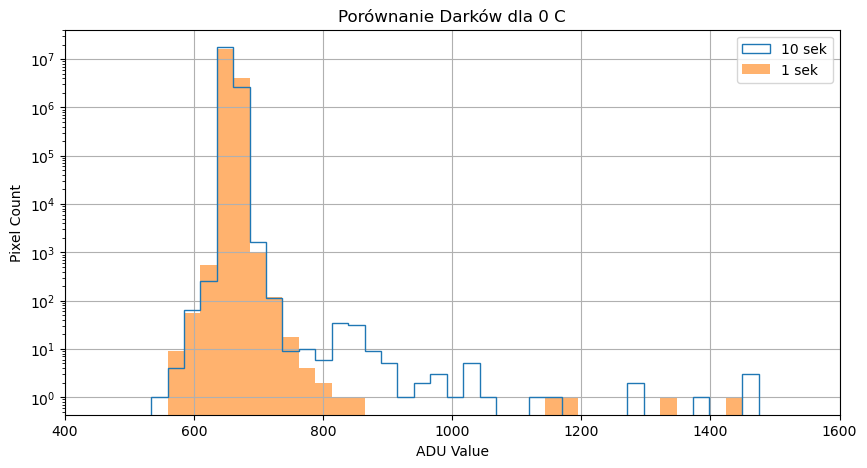

In [192]:
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 60)
plt.hist(dark0510_master.ravel(), histtype="step", bins=bins, alpha=1, label="10 sek")
plt.hist(dark051_master.ravel(), bins=bins, alpha=0.6, label="1 sek")
plt.xlim(400, 1600)
plt.yscale('log')
plt.title("Porównanie Darków dla 0 C")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()


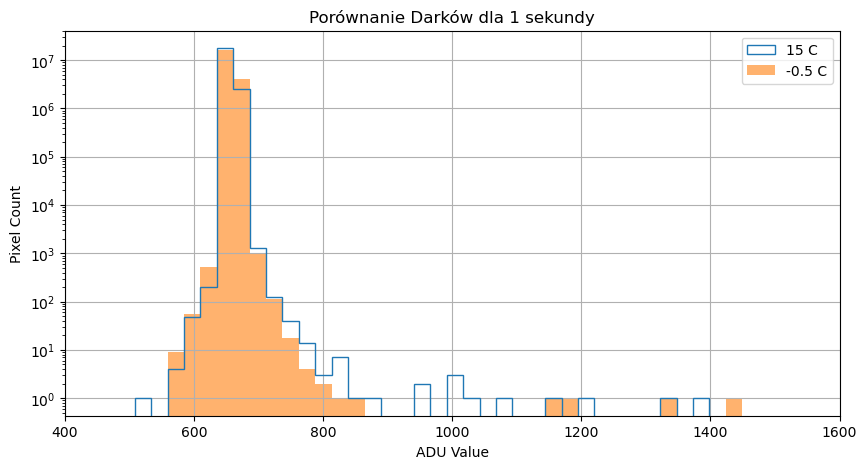

In [196]:
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 60)
plt.hist(dark151_master.ravel(), histtype="step", bins=bins, alpha=1, label="15 C")
plt.hist(dark051_master.ravel(), bins=bins, alpha=0.6, label="-0.5 C")
plt.xlim(400, 1600)
plt.yscale('log')
plt.title("Porównanie Darków dla 1 sekundy")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()

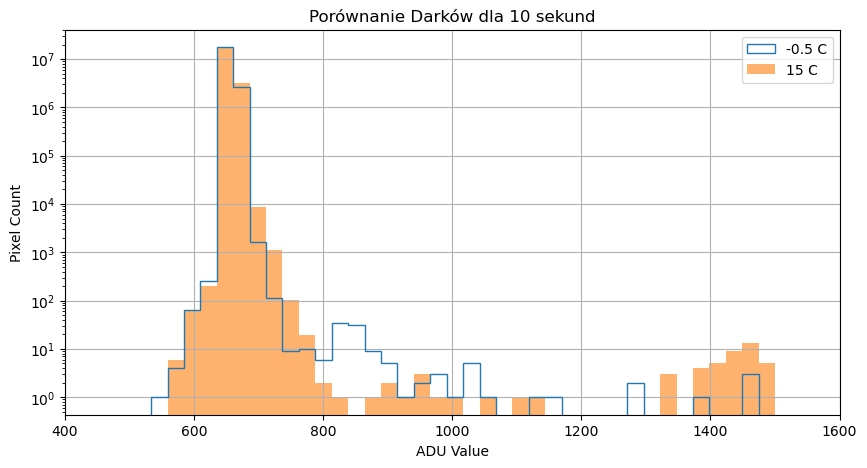

In [194]:
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 60)
plt.hist(dark0510_master.ravel(), histtype="step", bins=bins, alpha=1, label="-0.5 C")
plt.hist(dark1510_master.ravel(), bins=bins, alpha=0.6, label="15 C")
plt.xlim(400, 1600)
plt.yscale('log')
plt.title("Porównanie Darków dla 10 sekund")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()

In [4]:
header_bias1


SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 5496 / length of data axis 1                          
NAXIS2  =                 3672 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / physical = BZERO + BSCALE*array_value          
BSCALE  =                    1 / physical = BZERO + BSCALE*array_value          
XBINNING=                    1 / Binning factor in width                        
YBINNING=                    1 / Binning factor in height                       
EXPOINUS=                   